In [1]:
#| include: false
# Disable tqdm progress bars; this is a hidden cell on the docs page
import os

os.environ["TQDM_DISABLE"] = "1"

# Show the slice along my probe

`tilted_slice` cuts the plane through the atlas that contains a probe track, following its tilt, and returns the image with its extent in metres. With `axis=1` the plane is coronal-like, following the tilt in AP; with `axis=0` it is sagittal-like, following the tilt in ML.

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from iblatlas.atlas import AllenAtlas, Insertion

ba = AllenAtlas()

# Stand-in insertion: entry in left cortex, 15° from vertical, tilted out of the coronal plane.
# from_dict takes micrometres; replace it with your own insertion.
ins = Insertion.from_dict({'x': -2243, 'y': -2000, 'z': 0, 'phi': 210, 'theta': 15, 'depth': 4000},
                          brain_atlas=ba)

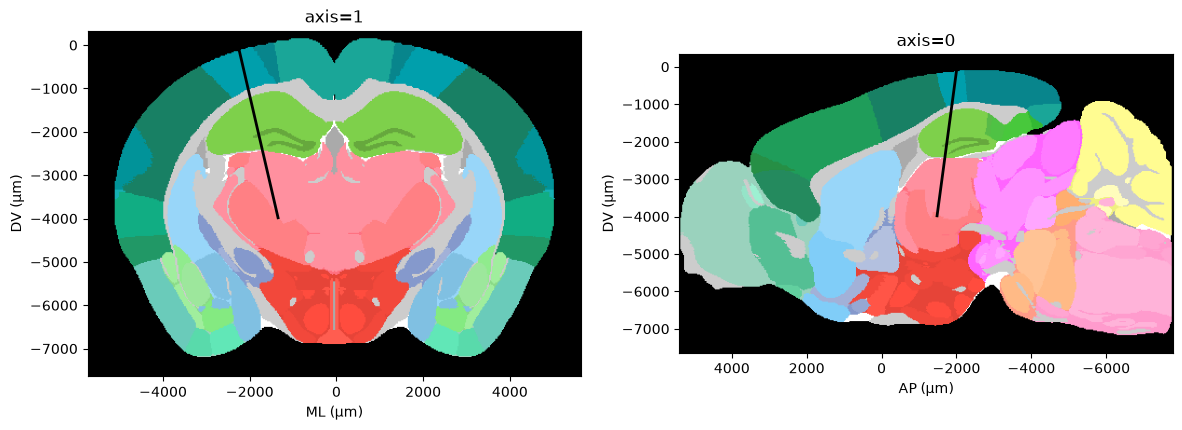

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# coronal-like plane: horizontal axis ML
tslice, width, height, _ = ba.tilted_slice(ins.xyz, axis=1, volume='annotation')
axs[0].imshow(tslice, extent=np.r_[width, height] * 1e6)
axs[0].plot(ins.xyz[:, 0] * 1e6, ins.xyz[:, 2] * 1e6, color='k', lw=2)
axs[0].set(xlabel='ML (µm)', ylabel='DV (µm)', title='axis=1')

# sagittal-like plane: horizontal axis AP
tslice, width, height, _ = ba.tilted_slice(ins.xyz, axis=0, volume='annotation')
axs[1].imshow(tslice, extent=np.r_[width, height] * 1e6)
axs[1].plot(ins.xyz[:, 1] * 1e6, ins.xyz[:, 2] * 1e6, color='k', lw=2)
axs[1].set(xlabel='AP (µm)', ylabel='DV (µm)', title='axis=0');

`volume='image'` gives the template image instead of the region colours. A volume of your own, with the shape of the atlas image, can be passed as `volume`; see [Show a 3D volume](plot-volumes-on-slices.ipynb#on-a-tilted-slice). The tutorial [From a target to a probe track](../tutorials/from-a-target-to-a-probe-track.ipynb) uses this slice to compare a planned and a reconstructed track.